# Évaluation des modèles de vision par ordinateur (version simple)
**Détection d'objets · Segmentation sémantique · Segmentation d'instance**

Ce notebook suit le plan de la présentation :

1. **Les tâches** : voir ce que produit chaque type de modèle sur une même image.
2. **Les métriques** : comprendre et calculer IoU, précision/rappel, AP/mAP, mIoU, Dice et PQ sur des petits exemples.
3. **L'évaluation réelle** : comparer des modèles pré-entraînés sur un vrai jeu de données.

*Conseils : exécutez les cellules **dans l'ordre**. Sur Google Colab, activez un GPU (Exécution → Modifier le type d'exécution). La partie 2 (métriques) fonctionne sans GPU.*

1. Voir ce que produit chaque type de modèle
Sur une même image (celle d’un bus), il fait tourner deux modèles pré-entraînés et compare trois tâches :

Détection d’objets (Mask R-CNN) : des boîtes avec une classe et un score.
Segmentation sémantique (DeepLabV3) : une classe pour chaque pixel, sans distinguer les individus.
Segmentation d’instance (Mask R-CNN) : un masque distinct par objet.

2. Comprendre et coder les métriques à la main (NumPy)

Précision, rappel, F1 : combien de bonnes détections, combien d’oublis.
IoU : le recouvrement entre une prédiction et la vérité terrain, la brique de base de tout le reste.
AP / mAP (norme COCO) : qualité d’un détecteur via la courbe précision-rappel, moyennée sur plusieurs seuils d’IoU.
mIoU, Dice, précision pixel : qualité d’une segmentation sémantique. Un exemple montre qu’un modèle inutile peut avoir 99 % de précision pixel mais un mIoU d’environ 50 %.
PQ (Panoptic Quality) : qualité des masques multipliée par qualité de reconnaissance.

Chaque métrique est testée sur de petits exemples dont on peut vérifier le résultat à la main.

3. Évaluer pour de vrai
Il télécharge le jeu de données Penn-Fudan (piétons) et évalue, sans entraînement, trois modèles pré-entraînés sur COCO : Mask R-CNN, SSDlite (léger) et DeepLabV3. Il produit :

un tableau de métriques (mAP, AP masque, PQ, mIoU, Dice),
les courbes précision-rappel,
un graphique du compromis précision/vitesse (latence, FPS, nombre de paramètres).


In [3]:
import time, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

try:
    import torch, torch.nn.functional as F, torchvision.transforms.functional as TF
    HAS_TORCH, device = True, ("cuda" if torch.cuda.is_available() else "cpu")
except ImportError:
    HAS_TORCH, device = False, "cpu"

N_IMAGES = 40                                  # nombre d'images évaluées en partie 3 (170 au maximum)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)

def download(url, dest):
    dest = Path(dest)
    if not dest.exists():
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
    return dest

def color_of(i):
    return plt.get_cmap("tab20")(int(i) % 20)[:3]

# Couleurs fixes et lisibles pour la segmentation sémantique (indices des classes Pascal VOC de DeepLabV3)
SEM_COLORS = {15: (0.89, 0.10, 0.11),    # personne = rouge
              6:  (0.12, 0.47, 0.71)}    # bus = bleu
BUS_COLOR = SEM_COLORS[6]

def colorize_labels(lab, cmap="tab10"):
    # carte d'étiquettes -> image couleur (0 = fond noir) ; couleurs fixes pour personne et bus
    cm = plt.get_cmap(cmap); rgb = np.zeros(lab.shape + (3,))
    for v in np.unique(lab):
        if v != 0: rgb[lab == v] = SEM_COLORS.get(int(v), cm(int(v) % cm.N)[:3])
    return rgb

print("PyTorch :", HAS_TORCH, "| périphérique :", device)

PyTorch : True | périphérique : cuda


## 1. Les tâches de vision

| Tâche | Question | Sortie du modèle |
|---|---|---|
| **Détection d'objets** | Quoi et où ? | boîtes + classe + score |
| **Segmentation sémantique** | Quelle classe pour chaque pixel ? | une carte de classes (deux personnes = même couleur) |
| **Segmentation d'instance** | Quel pixel pour quel objet ? | un masque par objet (chaque personne a sa couleur) |

On utilise **Mask R-CNN** (détection + instance) et **DeepLabV3** (sémantique), pré-entraînés.

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 171MB/s]


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 173MB/s]


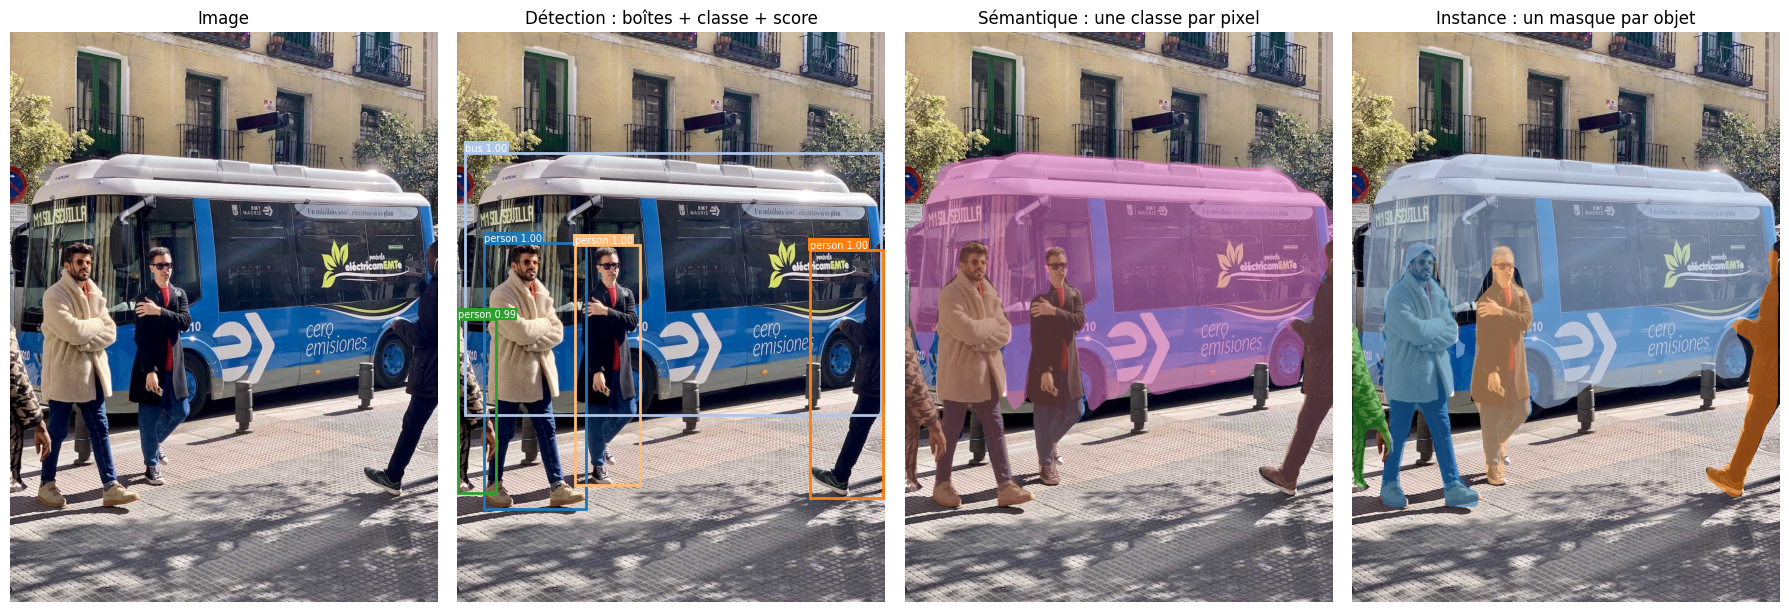

In [4]:
assert HAS_TORCH, "Cette cellule nécessite PyTorch."
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

# --- une image d'exemple ---
try:
    IMG = Image.open(download("https://ultralytics.com/images/bus.jpg", DATA_DIR / "bus.jpg")).convert("RGB")
except Exception:
    from skimage import data; IMG = Image.fromarray(data.astronaut())

# --- les deux modèles ---
w_seg = DeepLabV3_ResNet50_Weights.DEFAULT
det_model = maskrcnn_resnet50_fpn_v2(weights="DEFAULT").eval().to(device)
seg_model = deeplabv3_resnet50(weights=w_seg).eval().to(device)
COCO_NAMES = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT.meta["categories"]

with torch.no_grad():
    out = det_model([TF.to_tensor(IMG).to(device)])[0]                       # détection + instance
    keep = out["scores"] >= 0.5
    boxes, labels, scores = (out[k][keep].cpu().numpy() for k in ("boxes", "labels", "scores"))
    masks = (out["masks"][keep][:, 0] > 0.5).cpu().numpy()                   # (N, H, W)
    x = w_seg.transforms()(IMG).unsqueeze(0).to(device)                      # sémantique
    logits = F.interpolate(seg_model(x)["out"], size=IMG.size[::-1], mode="bilinear", align_corners=False)
    sem = logits.argmax(1)[0].cpu().numpy()                                  # (H, W)

img = np.asarray(IMG) / 255.0
fig, ax = plt.subplots(1, 4, figsize=(18, 6))
ax[0].imshow(img); ax[0].set_title("Image")
ax[1].imshow(img); ax[1].set_title("Détection : boîtes + classe + score")
for i, (b, l, s) in enumerate(zip(boxes, labels, scores)):
    ax[1].add_patch(Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec=color_of(i), lw=2))
    ax[1].text(b[0], b[1] - 4, f"{COCO_NAMES[l]} {s:.2f}", color="white", fontsize=7, bbox=dict(fc=color_of(i), ec="none", pad=1))
ax[2].imshow(np.where((sem > 0)[..., None], 0.45 * img + 0.55 * colorize_labels(sem), img)); ax[2].set_title("Sémantique : une classe par pixel")
inst = img.copy()
for i, m in enumerate(masks):
    # bus en bleu (comme en sémantique) ; chaque personne reçoit sa propre couleur
    col = np.array(BUS_COLOR) if COCO_NAMES[labels[i]] == "bus" else np.array(color_of(i + 2))
    inst[m] = 0.45 * inst[m] + 0.55 * col
ax[3].imshow(inst); ax[3].set_title("Instance : un masque par objet")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("figure_taches.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Les métriques d'évaluation
Toutes les métriques sont **codées à la main** avec NumPy et testées sur de petits exemples.

### 2.1 Précision, rappel et F1
- **TP** : objet réel bien détecté · **FP** : fausse alarme · **FN** : objet réel raté.

$$\text{Précision}=\frac{TP}{TP+FP}\quad\text{(quand il parle, a-t-il raison ?)}\qquad \text{Rappel}=\frac{TP}{TP+FN}\quad\text{(n'oublie-t-il rien ?)}\qquad F_1=\frac{2PR}{P+R}$$

In [5]:
def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

p, r, f1 = prf(tp=40, fp=10, fn=60)           # 100 objets réels, le modèle en annonce 50, dont 40 justes
print(f"Précision = {p:.2f} | Rappel = {r:.2f} | F1 = {f1:.2f}")

Précision = 0.80 | Rappel = 0.40 | F1 = 0.53


### 2.2 L'IoU (Intersection over Union)
$$\text{IoU}=\frac{\text{aire de l'intersection}}{\text{aire de l'union}}\in[0,1]$$
C'est le **concept commun** à toutes les tâches : il compare une prédiction à la vérité terrain, pour des **boîtes** (détection) comme pour des **masques** (segmentation). Une prédiction est « juste » si son IoU dépasse un seuil (0,5 en général).

À la main : 0.14285714285714285 | fonction : 0.14285714285714285


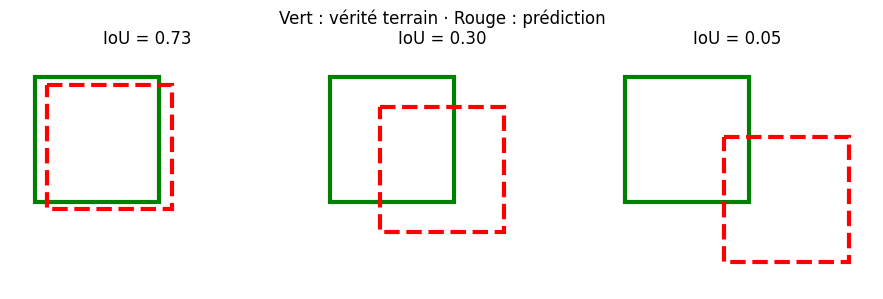

In [6]:
def box_iou(a, b):
    # IoU entre deux ensembles de boîtes (x1, y1, x2, y2) -> matrice (len(a), len(b))
    a = np.asarray(a, float).reshape(-1, 4); b = np.asarray(b, float).reshape(-1, 4)
    w = np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0])
    h = np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1])
    inter = np.clip(w, 0, None) * np.clip(h, 0, None)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

def mask_iou(a, b):
    # IoU entre deux ensembles de masques booléens (N, H, W) -> matrice (len(a), len(b))
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    A = a.reshape(len(a), -1).astype(np.float32); B = b.reshape(len(b), -1).astype(np.float32)
    inter = A @ B.T
    return inter / (A.sum(1)[:, None] + B.sum(1)[None, :] - inter)

# Calcul à la main : A = (0,0,10,10), B = (5,5,15,15) -> intersection 5x5 = 25 ; union = 100 + 100 - 25 = 175
print("À la main :", 25 / 175, "| fonction :", box_iou([(0, 0, 10, 10)], [(5, 5, 15, 15)])[0, 0])

# Illustration : plus la boîte prédite se décale, plus l'IoU baisse
gt = (0, 0, 10, 10)
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, d in zip(ax, [1, 4, 8]):
    pred = (d, 0.6 * d, 10 + d, 10 + 0.6 * d)
    a.add_patch(Rectangle(gt[:2], 10, 10, fill=False, ec="green", lw=3)); a.add_patch(Rectangle(pred[:2], 10, 10, fill=False, ec="red", lw=3, ls="--"))
    a.set_xlim(-2, 20); a.set_ylim(17, -2); a.set_aspect("equal"); a.axis("off")
    a.set_title(f"IoU = {box_iou([gt], [pred])[0, 0]:.2f}")
plt.suptitle("Vert : vérité terrain · Rouge : prédiction"); plt.tight_layout(); plt.show()

### 2.3 Détection : AP et mAP
Pour un détecteur, chaque détection a un **score de confiance**. On procède ainsi :
1. **Trier** les détections par score décroissant.
2. **Apparier** chacune à un objet réel non utilisé : **TP** si IoU ≥ seuil, sinon **FP**.
3. Calculer la **précision et le rappel cumulés** : c'est la **courbe précision-rappel**.
4. **AP** (Average Precision) = aire sous cette courbe. **mAP** = moyenne sur les classes.

Variantes : **AP@0.5** (seuil d'IoU indulgent), **AP@0.75** (strict), et **mAP@[.5:.95]** = moyenne sur 10 seuils d'IoU (0,50, 0,55…, 0,95) : c'est **la norme COCO**.

> *Vérification : cette implémentation donne exactement les mêmes résultats que l'outil officiel COCO (`pycocotools`) sur des données de test.*

In [7]:
def match_detections(scores, ious, thr):
    # Appariement glouton (règle COCO) : on parcourt les détections par score décroissant ;
    # chacune prend le meilleur objet réel encore libre si IoU >= thr. Renvoie (est_TP, indice_objet_apparié).
    tp = np.zeros(len(scores), bool); matched = -np.ones(len(scores), int); taken = np.zeros(ious.shape[1], bool)
    if ious.shape[1] == 0:
        return tp, matched
    for d in np.argsort(-scores, kind="stable"):
        cand = np.where(taken, -1.0, ious[d]); g = int(cand.argmax())
        if cand[g] >= thr:
            tp[d], matched[d], taken[g] = True, g, True
    return tp, matched

def average_precision(preds, gts, iou_fn, thr=0.5):
    # preds : une entrée par image = (objets prédits, scores) ; gts : une entrée par image = objets réels.
    # iou_fn : box_iou (détection) ou mask_iou (instance). Renvoie (AP, rappel, précision interpolée).
    all_scores, all_tp = [], []
    for (items, scores), g in zip(preds, gts):
        tp, _ = match_detections(scores, iou_fn(items, g), thr)
        all_scores.append(scores); all_tp.append(tp)
    scores, tp = np.concatenate(all_scores), np.concatenate(all_tp)
    order = np.argsort(-scores, kind="stable"); tp = tp[order].astype(float)
    tp_c, fp_c = np.cumsum(tp), np.cumsum(1 - tp)
    recall = tp_c / sum(len(g) for g in gts)
    precision = tp_c / (tp_c + fp_c)
    envelope = np.maximum.accumulate(precision[::-1])[::-1]               # enveloppe décroissante
    idx = np.searchsorted(recall, np.linspace(0, 1, 101), side="left")    # 101 niveaux de rappel (COCO)
    ap = np.mean([envelope[i] if i < len(envelope) else 0.0 for i in idx])
    return ap, recall, envelope

THRS = np.linspace(0.5, 0.95, 10)             # seuils d'IoU COCO

def coco_ap(preds, gts, iou_fn):
    aps = [average_precision(preds, gts, iou_fn, t)[0] for t in THRS]
    return dict(mAP=float(np.mean(aps)), AP50=float(aps[0]), AP75=float(aps[5]))

**Exemple fait à la main** : 3 images, 4 objets réels, 6 détections (2 fausses alarmes, 1 objet raté).

AP à IoU ≥ 0.5 : 0.505
AP à IoU ≥ 0.75 : 0.505
Résumé COCO : {'mAP': 0.379, 'AP50': 0.505, 'AP75': 0.505}


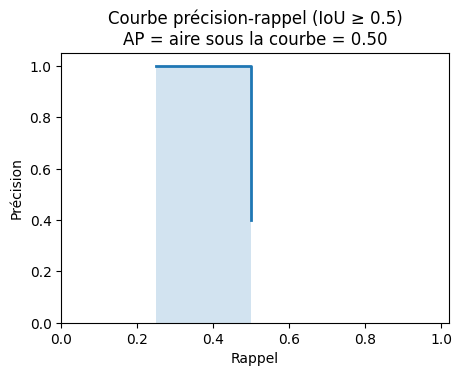

In [8]:
# (objets réels par image) et (boîtes prédites, scores) par image
toy_gts = [np.array([(10, 10, 60, 90), (100, 20, 160, 100)]),
           np.array([(30, 30, 90, 120)]),
           np.array([(50, 50, 120, 140)])]                                 # image 3 : objet jamais détecté
toy_preds = [(np.array([(12, 12, 62, 92), (98, 25, 158, 105), (200, 150, 250, 220)]), np.array([0.95, 0.90, 0.60])),
             (np.array([(55, 55, 115, 145), (0, 0, 40, 40)]), np.array([0.40, 0.30])),   # 1re : trop décalée
             (np.zeros((0, 4)), np.zeros(0))]

for t in (0.5, 0.75):
    ap, rec, prec = average_precision(toy_preds, toy_gts, box_iou, t)
    print(f"AP à IoU ≥ {t} : {ap:.3f}")
print("Résumé COCO :", {k: round(v, 3) for k, v in coco_ap(toy_preds, toy_gts, box_iou).items()})

ap, rec, prec = average_precision(toy_preds, toy_gts, box_iou, 0.5)
plt.figure(figsize=(5, 3.5)); plt.step(rec, prec, where="post", lw=2); plt.fill_between(rec, prec, step="post", alpha=0.2)
plt.xlim(0, 1.02); plt.ylim(0, 1.05); plt.xlabel("Rappel"); plt.ylabel("Précision")
plt.title(f"Courbe précision-rappel (IoU ≥ 0.5)\nAP = aire sous la courbe = {ap:.2f}"); plt.show()

### 2.4 Segmentation sémantique : précision pixel, mIoU, Dice
On compare deux cartes de classes. Tout se déduit de la **matrice de confusion** (lignes = vérité terrain, colonnes = prédiction) :

$$\text{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \text{mIoU}=\text{moyenne des IoU}_c\qquad \text{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}$$

⚠️ La **précision pixel** est trompeuse quand une classe domine (le fond). Le **mIoU** donne le même poids à chaque classe.

In [9]:
def confusion_matrix(gt, pred, n_classes):
    return np.bincount(n_classes * gt.ravel().astype(int) + pred.ravel().astype(int), minlength=n_classes ** 2).reshape(n_classes, n_classes)

def seg_metrics(cm):
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    iou = tp / (tp + fp + fn); dice = 2 * tp / (2 * tp + fp + fn)
    return dict(pixel_acc=tp.sum() / cm.sum(), mIoU=iou.mean(), IoU_objet=iou[-1], Dice_objet=dice[-1])

# Exemple : un petit objet (1 % des pixels) sur un grand fond
gt_map = np.zeros((100, 100), int); gt_map[40:50, 40:50] = 1
cases = {"A. Modèle inutile (tout en 'fond')": np.zeros((100, 100), int),
         "B. Objet trouvé mais décalé": np.roll(gt_map, 3, axis=1),
         "C. Segmentation parfaite": gt_map}
pd.DataFrame({name: seg_metrics(confusion_matrix(gt_map, pred, 2)) for name, pred in cases.items()}).T.round(3)

,pixel_acc,mIoU,IoU_objet,Dice_objet
A. Modèle inutile (tout en 'fond'),0.990,0.495,0.000,0.0
B. Objet trouvé mais décalé,0.994,0.766,0.538,0.7
C. Segmentation parfaite,1.000,1.000,1.000,1.0


→ Le modèle inutile (A) obtient **99 % de précision pixel**, mais son **mIoU est d'environ 50 %** : c'est le mIoU qui révèle l'échec.

### 2.5 Segmentation d'instance et panoptique : AP sur masques et PQ
- **Instance** : même AP que pour la détection, avec l'IoU calculé sur les **masques** (`average_precision(..., mask_iou)`).
- **Panoptique** : on mesure la **Panoptic Quality**, produit de deux facteurs lisibles. Un segment est apparié si son IoU est **> 0,5**.

$$\text{PQ}=\underbrace{\frac{\sum \text{IoU des TP}}{|TP|}}_{\text{SQ : qualité des masques}}\times\underbrace{\frac{|TP|}{|TP|+\frac12|FP|+\frac12|FN|}}_{\text{RQ : qualité de reconnaissance}}$$

In [10]:
def pq_counts(pred_masks, pred_scores, gt_masks):
    # (somme des IoU des TP, nb TP, nb FP, nb FN) pour une image
    ious = mask_iou(pred_masks, gt_masks)
    tp, matched = match_detections(pred_scores, ious, 0.5 + 1e-9)
    return np.array([sum(ious[d, matched[d]] for d in np.where(tp)[0]), tp.sum(), (~tp).sum(), len(gt_masks) - tp.sum()], float)

def pq_scores(sum_iou, tp, fp, fn):
    sq = sum_iou / tp if tp else 0.0
    rq = tp / (tp + 0.5 * fp + 0.5 * fn) if tp + fp + fn else 0.0
    return dict(PQ=float(sq * rq), SQ=float(sq), RQ=float(rq))

def rect_mask(x1, y1, x2, y2, shape=(100, 100)):
    m = np.zeros(shape, bool); m[y1:y2, x1:x2] = True; return m

# 3 objets réels ; le modèle en segmente bien 1, place mal un 2e, et oublie le 3e
gt_m = np.array([rect_mask(10, 10, 40, 40), rect_mask(50, 10, 90, 50), rect_mask(20, 60, 60, 95)])
pr_m = np.array([rect_mask(12, 12, 42, 42), rect_mask(70, 30, 95, 55)])
c = pq_counts(pr_m, np.array([0.9, 0.8]), gt_m)
print(f"TP={int(c[1])}, FP={int(c[2])}, FN={int(c[3])} ->", {k: round(v, 3) for k, v in pq_scores(*c).items()})
print("Contrôle : RQ = 1 / (1 + 0.5×1 + 0.5×2) =", round(1 / 2.5, 3))

TP=1, FP=1, FN=2 -> {'PQ': 0.309, 'SQ': 0.772, 'RQ': 0.4}
Contrôle : RQ = 1 / (1 + 0.5×1 + 0.5×2) = 0.4


### 2.6 Récapitulatif : quelle métrique pour quelle tâche ?

| Tâche | Sortie du modèle | Métriques principales | Appariement |
|---|---|---|---|
| Détection d'objets | boîtes + classe + score | AP@0.5, AP@0.75, **mAP@[.5:.95]** | IoU de boîtes |
| Segmentation sémantique | une classe par pixel | **mIoU**, Dice, précision pixel | IoU par classe |
| Segmentation d'instance | un masque par objet + score | **AP masque** | IoU de masques |
| Panoptique | instances + régions | **PQ** = SQ × RQ | IoU de segments > 0,5 |
| Tous (déploiement) | – | latence, FPS, nombre de paramètres | – |

## 3. Évaluation réelle sur un jeu de données
On utilise **Penn-Fudan** (170 images de piétons, ~50 Mo), qui fournit les **boîtes, masques d'instance et masques sémantiques**. Les modèles sont pré-entraînés sur COCO et évalués **tels quels** sur la classe « personne » (aucun entraînement).

Autres benchmarks de référence : **COCO** (détection, instance), **Pascal VOC**, **Cityscapes** et **ADE20K** (segmentation).

In [11]:
PENN_URLS = ["https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip",
             "https://vrl.sys.wakayama-u.ac.jp/class/pytorch_tutorial/datasets/PennFudanPed.zip"]

def make_sample(img, masks):
    # un échantillon = image + vérité terrain (masques, boîtes, carte sémantique)
    masks = masks[masks.reshape(len(masks), -1).any(1)]
    boxes = np.array([[xs.min(), ys.min(), xs.max() + 1, ys.max() + 1] for ys, xs in (np.where(m) for m in masks)], float).reshape(-1, 4)
    return dict(image=img, masks=masks, boxes=boxes, semantic=masks.any(0).astype(np.uint8))

def load_pennfudan(n):
    root = DATA_DIR / "PennFudanPed"
    if not root.exists():
        for url in PENN_URLS:
            try:
                zipfile.ZipFile(download(url, DATA_DIR / "PennFudanPed.zip")).extractall(DATA_DIR); break
            except Exception as e:
                print("Échec :", url, "->", e); (DATA_DIR / "PennFudanPed.zip").unlink(missing_ok=True)
        else:
            raise RuntimeError("Téléchargement impossible : téléchargez PennFudanPed.zip depuis https://www.cis.upenn.edu/~jshi/ped_html/ "
                               f"et décompressez-le dans {DATA_DIR}/")
    imgs = sorted((root / "PNGImages").glob("*.png")); msks = sorted((root / "PedMasks").glob("*_mask.png"))
    pick = np.sort(np.random.default_rng(0).choice(len(imgs), size=min(n, len(imgs)), replace=False))
    out = []
    for i in pick:
        m = np.array(Image.open(msks[i])); ids = np.unique(m)[1:]                 # 0 = fond, 1..N = piétons
        out.append(make_sample(Image.open(imgs[i]).convert("RGB"), m[None] == ids[:, None, None]))
    return out

samples = load_pennfudan(N_IMAGES)
print(f"{len(samples)} images, {sum(len(s['masks']) for s in samples)} piétons annotés")

40 images, 104 piétons annotés


### 3.1 Lancer les modèles
- **Mask R-CNN** : précis, fournit boîtes **et** masques.
- **SSDlite** : modèle léger et rapide, boîtes seulement.
- **DeepLabV3** : segmentation sémantique.

On garde la classe « personne » et **toutes les détections de score > 0,05** (nécessaire pour tracer la courbe précision-rappel). La vitesse est mesurée au passage.

In [12]:
assert HAS_TORCH, "Cette cellule nécessite PyTorch."
from torchvision.models.detection import ssdlite320_mobilenet_v3_large

def sync():
    if device == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def run_detector(model, samples, person=1):                  # 1 = classe 'person' dans COCO
    model = model.to(device).eval(); preds, times = [], []
    for s in samples:
        x = TF.to_tensor(s["image"]).to(device)
        sync(); t0 = time.perf_counter(); out = model([x])[0]; sync(); times.append(time.perf_counter() - t0)
        k = (out["labels"] == person).cpu().numpy()
        p = dict(boxes=out["boxes"].cpu().numpy()[k], scores=out["scores"].cpu().numpy()[k])
        if "masks" in out: p["masks"] = (out["masks"][:, 0] > 0.5).cpu().numpy()[k]
        preds.append(p)
    return preds, float(np.mean(times[1:]) * 1000)           # la 1re image sert d'échauffement

@torch.no_grad()
def run_deeplab(model, samples):
    person = w_seg.meta["categories"].index("person"); maps, times = [], []
    for s in samples:
        x = w_seg.transforms()(s["image"]).unsqueeze(0).to(device)
        sync(); t0 = time.perf_counter()
        pred = F.interpolate(model(x)["out"], size=s["image"].size[::-1], mode="bilinear", align_corners=False).argmax(1)[0]
        sync(); times.append(time.perf_counter() - t0)
        maps.append((pred == person).cpu().numpy().astype(np.uint8))
    return maps, float(np.mean(times[1:]) * 1000)

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6        # en millions

PREDS, LAT, PARAMS = {}, {}, {}
for name, model in {"Mask R-CNN": det_model, "SSDlite (léger)": ssdlite320_mobilenet_v3_large(weights="DEFAULT")}.items():
    PREDS[name], LAT[name] = run_detector(model, samples); PARAMS[name] = n_params(model)
    print(f"{name:18s} {LAT[name]:6.1f} ms/image | {PARAMS[name]:5.1f} M paramètres")
SEM_MAPS, SEM_LAT = run_deeplab(seg_model, samples)

Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 97.1MB/s]


Mask R-CNN          164.6 ms/image |  46.4 M paramètres
SSDlite (léger)      37.8 ms/image |   3.4 M paramètres


### 3.2 Résultats

In [ ]:
gt_boxes = [s["boxes"] for s in samples]; gt_masks = [s["masks"] for s in samples]

def pq_dataset(preds, thr=0.5):
    tot = np.zeros(4)
    for p, s in zip(preds, samples):
        k = p["scores"] >= thr; tot += pq_counts(p["masks"][k], p["scores"][k], s["masks"])
    return pq_scores(*tot)

# --- Détection (boîtes) et instance (masques) ---
rows = {}
for name, preds in PREDS.items():
    box = coco_ap([(p["boxes"], p["scores"]) for p in preds], gt_boxes, box_iou)
    row = {"mAP@[.5:.95]": box["mAP"], "AP@0.5": box["AP50"], "AP@0.75": box["AP75"]}
    if "masks" in preds[0]:
        row["AP masque@[.5:.95]"] = coco_ap([(p["masks"], p["scores"]) for p in preds], gt_masks, mask_iou)["mAP"]
        row["PQ (score ≥ 0.5)"] = pq_dataset(preds)["PQ"]
    row.update({"Latence (ms)": LAT[name], "FPS": 1000 / LAT[name], "Paramètres (M)": PARAMS[name]})
    rows[name] = row
df_det = pd.DataFrame(rows).T
display(df_det.round(3).fillna("–"))

# --- Segmentation sémantique (personne vs fond), matrice de confusion cumulée sur tout le jeu ---
cm = sum(confusion_matrix(s["semantic"], m, 2) for s, m in zip(samples, SEM_MAPS))
sm = seg_metrics(cm)
display(pd.DataFrame({"DeepLabV3": {"mIoU": sm["mIoU"], "IoU personne": sm["IoU_objet"], "Dice personne": sm["Dice_objet"],
                                    "Précision pixel": sm["pixel_acc"], "Latence (ms)": SEM_LAT}}).T.round(3))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, preds in PREDS.items():                            # courbes précision-rappel (IoU >= 0.5)
    ap, rec, prec = average_precision([(p["boxes"], p["scores"]) for p in preds], gt_boxes, box_iou, 0.5)
    ax[0].step(rec, prec, where="post", lw=2, label=f"{name} (AP@0.5 = {ap:.2f})")
ax[0].set(xlabel="Rappel", ylabel="Précision", title="Courbes précision-rappel", xlim=(0, 1.02), ylim=(0, 1.05)); ax[0].legend(loc="lower left")
for name, row in df_det.iterrows():                          # compromis précision / vitesse
    ax[1].scatter(row["FPS"], row["mAP@[.5:.95]"], s=60 + 8 * row["Paramètres (M)"], alpha=0.7)
    ax[1].annotate(name, (row["FPS"], row["mAP@[.5:.95]"]), xytext=(8, 8), textcoords="offset points")
ax[1].set(xlabel=f"Vitesse (images/s, {device})", ylabel="mAP@[.5:.95]", title="Compromis précision / vitesse")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Comment lire ces résultats**
- Comparez **AP@0.5** et **mAP@[.5:.95]** : un écart important signifie que le modèle trouve les objets mais les **localise moins précisément**.
- L'**AP masque** est généralement plus bas que l'AP des boîtes : tracer un contour précis est plus difficile.
- Le **PQ** dépend du seuil de score choisi, et les piétons non annotés dans le jeu comptent comme faux positifs.
- La **vitesse** dépend de votre matériel : citez-le toujours, et comparez les modèles entre eux plutôt que les valeurs absolues.
- Avec peu d'images et une seule classe, ces chiffres **illustrent la méthode** : ce n'est pas un benchmark.

## 4. Conclusion

1. **Tout commence par l'IoU** : une prédiction est « juste » si elle chevauche assez la vérité terrain (boîtes ou masques).
2. **La bonne métrique dépend de la tâche** : mAP (détection), mIoU/Dice (sémantique), AP masque (instance), PQ (panoptique).
3. **Ne jamais se fier à un seul chiffre** : 99 % de précision pixel peut cacher un modèle inutile, et l'AP@0.5 est plus indulgente que le mAP@[.5:.95].
4. **Le meilleur modèle dépend du contexte** : un modèle léger moins précis peut être préférable en temps réel.

**Références** : Lin et al., *Microsoft COCO* (2014) · Everingham et al., *Pascal VOC* (2010) · Kirillov et al., *Panoptic Segmentation* (2019) · He et al., *Mask R-CNN* (2017) · Chen et al., *DeepLab* (2018).